# HQViT — Clean Restart Notebook
**Data-Efficient Image Classification Using a Hybrid Quantum-Classical Vision Transformer**  
CIFAR-10 · CPU-first · maximum 15 epochs.

This is a clean, linear replacement for the fragmented notebook. It preserves the original split procedure from Cells 12–13. It does not overwrite historical results or claim that the rebuilt HQViT is identical to the lost historical model/checkpoint.

**Important:** The original split seed must be recovered from `results/experiment_config.json` or entered explicitly. The notebook stops rather than guessing. The test set is reserved for final evaluation. Training is opt-in.

## 1. Imports and environment

In [1]:
import os, sys, json, time, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset, random_split
import pennylane as qml
from sklearn.metrics import accuracy_score, classification_report

warnings.filterwarnings("ignore")
DEVICE = torch.device("cpu")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("PennyLane:", qml.__version__)
print("Device:", DEVICE)

Python: 3.14.2
PyTorch: 2.15.0+cu132
Torchvision: 0.29.2+cu132
PennyLane: 0.45.1
Device: cpu


## 2. Configuration and seed recovery

In [2]:
CONFIG_PATH = Path("results/experiment_config.json")
ORIGINAL_SEED = None  # If config is missing, enter the exact original SEED here.

if CONFIG_PATH.exists():
    with open(CONFIG_PATH) as f:
        saved_config = json.load(f)
    if "seed" in saved_config:
        ORIGINAL_SEED = int(saved_config["seed"])

if ORIGINAL_SEED is None:
    raise RuntimeError(
        "Original seed not found. Set ORIGINAL_SEED to the exact SEED "
        "from the original notebook. Do not guess."
    )

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
BATCH_SIZE, MAX_EPOCHS = 32, 15
LEARNING_RATE, WEIGHT_DECAY = 1e-4, 1e-4
DATA_FRACTIONS = (0.10, 0.25, 0.50, 1.00)
DATA_DIR = Path("data")
RESULTS_DIR = Path("results_clean")
CHECKPOINT_DIR = Path("checkpoints_clean")
RESULTS_DIR.mkdir(exist_ok=True, parents=True)
CHECKPOINT_DIR.mkdir(exist_ok=True, parents=True)
print("Original seed:", SEED)

Original seed: 42


## 3. CIFAR-10 and original split reconstruction

In [3]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

full_train_dataset = datasets.CIFAR10(
    root=str(DATA_DIR), train=True, download=True, transform=transform
)
test_dataset = datasets.CIFAR10(
    root=str(DATA_DIR), train=False, download=True, transform=transform
)
assert len(full_train_dataset) == 50000 and len(test_dataset) == 10000

# Original Cell 12: PyTorch random_split with seeded Generator.
split_generator = torch.Generator().manual_seed(SEED)
train_pool, validation_dataset = random_split(
    full_train_dataset, [45000, 5000], generator=split_generator
)

# Original Cell 13: independently seeded NumPy permutation of train_pool.
pool_order = np.random.default_rng(SEED).permutation(len(train_pool))
train_subsets = {
    f: Subset(train_pool, pool_order[:int(len(train_pool)*f)].tolist())
    for f in DATA_FRACTIONS
}
train_indices = list(train_pool.indices)
validation_indices = list(validation_dataset.indices)
assert not (set(train_indices) & set(validation_indices))
assert len(set(train_indices + validation_indices)) == 50000

print("Train pool:", len(train_pool), "| Validation:", len(validation_dataset),
      "| Test:", len(test_dataset))
for f, ds in train_subsets.items(): print(f"{f:.0%}:", len(ds))

100.0%


Train pool: 45000 | Validation: 5000 | Test: 10000
10%: 4500
25%: 11250
50%: 22500
100%: 45000


## 4. Loaders and sanity check

In [4]:
def make_loaders(fraction=1.0, batch_size=BATCH_SIZE):
    tr = DataLoader(train_subsets[fraction], batch_size=batch_size,
                    shuffle=True, num_workers=0)
    va = DataLoader(validation_dataset, batch_size=batch_size,
                    shuffle=False, num_workers=0)
    return tr, va

train_loader, validation_loader = make_loaders(0.10)
x, y = next(iter(train_loader))
print("Batch:", tuple(x.shape), tuple(y.shape),
      "| finite:", bool(torch.isfinite(x).all()))
assert x.shape[1:] == (3, 32, 32) and torch.isfinite(x).all()

Batch: (32, 3, 32, 32) (32,) | finite: True


## 5. Model definitions

The comparison consists of a Classical ViT, a classical 4-dimensional bottleneck control, and a rebuilt 4-qubit HQViT. All are freshly initialized. The HQViT is the documented rebuilt implementation, **not** a reproduction of the missing historical weights.

In [5]:
class ViTBackbone(nn.Module):
    def __init__(self, dim=128, heads=4, layers=4, patch=4, dropout=0.1):
        super().__init__()
        self.patch_embed = nn.Conv2d(3, dim, kernel_size=patch, stride=patch)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, 65, dim))
        self.dropout = nn.Dropout(dropout)
        enc = nn.TransformerEncoderLayer(
            d_model=dim, nhead=heads, dim_feedforward=4*dim,
            dropout=dropout, batch_first=True, activation="gelu"
        )
        self.transformer = nn.TransformerEncoder(enc, num_layers=layers)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

    def forward(self, x):
        x = self.patch_embed(x).flatten(2).transpose(1, 2)
        cls = self.cls_token.expand(x.size(0), -1, -1)
        x = self.dropout(torch.cat([cls, x], dim=1) + self.pos_embed)
        return self.transformer(x)[:, 0]

class ClassicalViT(nn.Module):
    def __init__(self):
        super().__init__()
        self.vit = ViTBackbone()
        self.head = nn.Linear(128, 10)
    def forward(self, x): return self.head(self.vit(x))

class ClassicalBottleneck(nn.Module):
    def __init__(self):
        super().__init__()
        self.vit = ViTBackbone()
        self.projection_norm = nn.LayerNorm(128)
        self.projection = nn.Linear(128, 4)
        self.classical_transform = nn.Sequential(nn.Linear(4, 4), nn.Tanh())
        self.classifier = nn.Sequential(nn.Linear(4, 32), nn.GELU(), nn.Linear(32, 10))
    def forward(self, x):
        z = self.projection(self.projection_norm(self.vit(x)))
        return self.classifier(self.classical_transform(z))

N_QUBITS, Q_LAYERS = 4, 2
qdev = qml.device("default.qubit", wires=N_QUBITS, shots=None)

@qml.qnode(qdev, interface="torch", diff_method="backprop")
def quantum_circuit(inputs, weights):
    for w in range(N_QUBITS): qml.RY(inputs[w], wires=w)
    for layer in range(Q_LAYERS):
        for w in range(N_QUBITS):
            qml.RY(weights[layer, w, 0], wires=w)
            qml.RZ(weights[layer, w, 1], wires=w)
        for w in range(N_QUBITS-1): qml.CNOT(wires=[w, w+1])
    return [qml.expval(qml.PauliZ(w)) for w in range(N_QUBITS)]

class HQViT(nn.Module):
    def __init__(self):
        super().__init__()
        self.vit = ViTBackbone()
        self.projection_norm = nn.LayerNorm(128)
        self.projection = nn.Linear(128, N_QUBITS)
        self.quantum_weights = nn.Parameter(0.01 * torch.randn(Q_LAYERS, N_QUBITS, 2))
        self.classifier = nn.Sequential(nn.Linear(4, 32), nn.GELU(), nn.Linear(32, 10))
    def forward(self, x):
        z = self.projection(self.projection_norm(self.vit(x)))
        q = torch.stack([torch.stack(quantum_circuit(row, self.quantum_weights)) for row in z])
        return self.classifier(q.to(dtype=z.dtype, device=z.device))

def parameter_count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

for cls in (ClassicalViT, ClassicalBottleneck, HQViT):
    m = cls()
    print(cls.__name__, parameter_count(m), "trainable parameters")
    del m

ClassicalViT 809098 trainable parameters
ClassicalBottleneck 809090 trainable parameters
HQViT 809086 trainable parameters


## 6. Smoke test (forward + backward)

In [6]:
# Tiny batch only; validates shapes and gradient flow, not model quality.
sx, sy = next(iter(DataLoader(Subset(train_subsets[0.10], range(4)),
                              batch_size=4, shuffle=False)))
for cls in (ClassicalViT, ClassicalBottleneck, HQViT):
    model = cls().to(DEVICE)
    model.zero_grad(set_to_none=True)
    logits = model(sx)
    loss = nn.CrossEntropyLoss()(logits, sy)
    loss.backward()
    finite_grads = all(p.grad is None or torch.isfinite(p.grad).all()
                       for p in model.parameters())
    print(cls.__name__, logits.shape, "finite output:", bool(torch.isfinite(logits).all()),
          "finite gradients:", bool(finite_grads))
    assert logits.shape == (4, 10) and torch.isfinite(logits).all() and finite_grads
    del model

ClassicalViT torch.Size([4, 10]) finite output: True finite gradients: True
ClassicalBottleneck torch.Size([4, 10]) finite output: True finite gradients: True
HQViT torch.Size([4, 10]) finite output: True finite gradients: True


## 7. Training utilities

In [7]:
def evaluate(model, loader):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    criterion = nn.CrossEntropyLoss()
    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb.to(DEVICE))
            yb = yb.to(DEVICE)
            loss_sum += criterion(logits, yb).item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            total += len(yb)
    return loss_sum/total, correct/total

def train_model(model, name, fraction=0.10, epochs=1):
    epochs = min(int(epochs), MAX_EPOCHS)
    tr_loader, va_loader = make_loaders(fraction)
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE,
                                  weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()
    rows, best_acc = [], -1.0
    ckpt = CHECKPOINT_DIR / f"{name}_{int(fraction*100)}pct_best.pt"

    for epoch in range(1, epochs+1):
        start = time.time()
        model.train()
        loss_sum, correct, total = 0.0, 0, 0
        for xb, yb in tr_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item()*len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            total += len(yb)
        val_loss, val_acc = evaluate(model, va_loader)
        row = dict(model=name, fraction=fraction, epoch=epoch,
                   train_loss=loss_sum/total, train_accuracy=correct/total,
                   validation_loss=val_loss, validation_accuracy=val_acc,
                   epoch_seconds=time.time()-start)
        rows.append(row)
        pd.DataFrame(rows).to_csv(RESULTS_DIR/f"{name}_{int(fraction*100)}pct.csv",
                                  index=False)
        print(f"{name} {epoch}/{epochs} train={correct/total:.4f} "
              f"val={val_acc:.4f} time={row['epoch_seconds']:.1f}s")
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save({"model_state_dict": model.state_dict(), **row, "seed": SEED}, ckpt)
    return model, pd.DataFrame(rows), ckpt

## 8. Run experiments — deliberately disabled by default

The historical Classical ViT completed 15 epochs: best validation accuracy **68.16% at epoch 12**, final validation accuracy **67.88%**. Its 71.54% figure was training accuracy, not validation accuracy. Preserve those results; do not retrain or overwrite them by default.

The HQViT evaluates a quantum circuit per sample and may be very slow on CPU. Begin with one epoch on 10% data.

In [13]:
RUN_EXPERIMENTS = True
RUN_FRACTION = 0.10
RUN_EPOCHS = 15  # never more than 15

if RUN_EXPERIMENTS:
    # Uncomment exactly ONE model run at a time.
    m, hist, path = train_model(ClassicalBottleneck(), "classical_bottleneck",
                                 RUN_FRACTION, RUN_EPOCHS)
    # m, hist, path = train_model(HQViT(), "rebuilt_hqvit",
    #                             RUN_FRACTION, RUN_EPOCHS)
    print("Activate one explicit train_model(...) call above.")
else:
    print("Training disabled. Setup and smoke tests only.")

classical_bottleneck 1/15 train=0.1511 val=0.1642 time=52.4s
classical_bottleneck 2/15 train=0.1633 val=0.1800 time=58.7s
classical_bottleneck 3/15 train=0.2156 val=0.2550 time=57.6s
classical_bottleneck 4/15 train=0.2418 val=0.2508 time=52.4s
classical_bottleneck 5/15 train=0.2516 val=0.2624 time=52.5s
classical_bottleneck 6/15 train=0.2618 val=0.2594 time=54.0s
classical_bottleneck 7/15 train=0.2731 val=0.2848 time=54.9s
classical_bottleneck 8/15 train=0.2876 val=0.2786 time=54.1s
classical_bottleneck 9/15 train=0.3013 val=0.2860 time=54.0s
classical_bottleneck 10/15 train=0.3049 val=0.2862 time=55.2s
classical_bottleneck 11/15 train=0.3109 val=0.2948 time=55.2s
classical_bottleneck 12/15 train=0.3136 val=0.2890 time=53.4s
classical_bottleneck 13/15 train=0.3324 val=0.3032 time=53.7s
classical_bottleneck 14/15 train=0.3293 val=0.3026 time=54.0s
classical_bottleneck 15/15 train=0.3384 val=0.3032 time=53.3s
Activate one explicit train_model(...) call above.


In [21]:
RUN_EXPERIMENTS = True
RUN_FRACTION = 0.10
RUN_EPOCHS = 15  # never more than 15

if RUN_EXPERIMENTS:
    # Uncomment exactly ONE model run at a time.
    #m, hist, path = train_model(ClassicalBottleneck(), "classical_bottleneck",
    #                             RUN_FRACTION, RUN_EPOCHS)
    m, hist, path = train_model(HQViT(), "rebuilt_hqvit",
                                 RUN_FRACTION, RUN_EPOCHS)
    print("Activate one explicit train_model(...) call above.")
else:
    print("Training disabled. Setup and smoke tests only.")

rebuilt_hqvit 1/15 train=0.1289 val=0.1444 time=150.5s
rebuilt_hqvit 2/15 train=0.1593 val=0.1416 time=151.6s
rebuilt_hqvit 3/15 train=0.1980 val=0.2210 time=150.7s
rebuilt_hqvit 4/15 train=0.2316 val=0.2172 time=152.5s
rebuilt_hqvit 5/15 train=0.2287 val=0.2080 time=152.1s
rebuilt_hqvit 6/15 train=0.2249 val=0.2150 time=149.9s
rebuilt_hqvit 7/15 train=0.2278 val=0.2302 time=150.0s
rebuilt_hqvit 8/15 train=0.2362 val=0.2134 time=149.3s
rebuilt_hqvit 9/15 train=0.2427 val=0.2420 time=148.5s
rebuilt_hqvit 10/15 train=0.2464 val=0.2354 time=150.7s
rebuilt_hqvit 11/15 train=0.2651 val=0.2628 time=152.2s
rebuilt_hqvit 12/15 train=0.2760 val=0.2688 time=151.5s
rebuilt_hqvit 13/15 train=0.2909 val=0.2538 time=151.2s
rebuilt_hqvit 14/15 train=0.2958 val=0.2826 time=153.6s
rebuilt_hqvit 15/15 train=0.3000 val=0.2900 time=150.4s
Activate one explicit train_model(...) call above.


## 9. Load checkpoints

In [18]:
def load_checkpoint(model, path):
    saved = torch.load(path, map_location=DEVICE)
    model.load_state_dict(saved["model_state_dict"])
    model.to(DEVICE).eval()
    print("Loaded:", path)
    print("Metadata:", {k:v for k,v in saved.items() if k != "model_state_dict"})
    return model

# Example:
classical_bottleneck_model = load_checkpoint(ClassicalBottleneck(),
     "checkpoints_clean/classical_bottleneck_10pct_best.pt")

Loaded: checkpoints_clean/classical_bottleneck_10pct_best.pt
Metadata: {'model': 'classical_bottleneck', 'fraction': 0.1, 'epoch': 13, 'train_loss': 1.8011880702972412, 'train_accuracy': 0.33244444444444443, 'validation_loss': 1.85093145942688, 'validation_accuracy': 0.3032, 'epoch_seconds': 53.6706817150116, 'seed': 42}


In [30]:
import os
import json
import torch
from datetime import datetime

os.makedirs("models_clean/final_hqvit", exist_ok=True)
os.makedirs("results/final_hqvit", exist_ok=True)

# Save model checkpoint
checkpoint_path = "models_clean/final_hqvit/rebuilt_hqvit_final.pt"

torch.save({
    "model_state_dict": HQViT.state_dict(),
    "model_class": "HQViT",
    "model_parameters": sum(p.numel() for p in HQViT.parameters()),
    "epochs_completed": 15,
    "final_train_accuracy": 0.3000,
    "final_validation_accuracy": 0.2900,
    "saved_at": datetime.now().isoformat()
}, checkpoint_path)

# Save configuration separately (JSON-compatible values only)
config = {
    "model": "HQViT",
    "architecture": "Rebuilt CorrectedHybridQuantumViT",
    "parameters": sum(p.numel() for p in HQViT.parameters()),
    "dataset": "CIFAR-10",
    "epochs_completed": 15,
    "final_train_accuracy": 0.3000,
    "final_validation_accuracy": 0.2900,
    "device": str(next(HQViT.parameters()).device),
    "saved_at": datetime.now().isoformat()
}

config_path = "results/final_hqvit/experiment_config.json"

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

# Verify checkpoint
saved = torch.load(checkpoint_path, map_location="cpu", weights_only=False)

print("========== SAVE VERIFIED ==========")
print("Checkpoint:", checkpoint_path)
print("Configuration:", config_path)
print("Model parameters:", f"{config['parameters']:,}")
print("Checkpoint keys:", list(saved.keys()))
print("Status: SUCCESS")

========== SAVE VERIFIED ==========
Checkpoint: models_clean/final_hqvit/rebuilt_hqvit_final.pt
Configuration: results/final_hqvit/experiment_config.json
Model parameters: 809,086
Checkpoint keys: ['model_state_dict', 'model_class', 'model_parameters', 'epochs_completed', 'final_train_accuracy', 'final_validation_accuracy', 'saved_at']
Status: SUCCESS


In [28]:
import torch

print("Searching for trained HQViT model...\n")

for name, obj in list(globals().items()):
    try:
        if isinstance(obj, torch.nn.Module):
            print(
                f"Variable: {name} | "
                f"Class: {obj.__class__.__name__} | "
                f"Parameters: {sum(p.numel() for p in obj.parameters()):,}"
            )
    except Exception:
        pass

Searching for trained HQViT model...

Variable: HQViT | Class: HQViT | Parameters: 809,086
Variable: m | Class: HQViT | Parameters: 809,086
Variable: classical_bottleneck_model | Class: ClassicalBottleneck | Parameters: 809,090


## 10. Final test evaluation — only after model selection

In [10]:
def final_test_evaluation(model):
    # Do not use test metrics to tune or select models.
    loader = DataLoader(test_dataset, batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=0)
    y_true, y_pred = [], []
    model.eval()
    with torch.no_grad():
        for xb, yb in loader:
            pred = model(xb.to(DEVICE)).argmax(1).cpu().numpy()
            y_pred.extend(pred.tolist())
            y_true.extend(yb.numpy().tolist())
    print("Test accuracy:", accuracy_score(y_true, y_pred))
    print(classification_report(y_true, y_pred, digits=4))
    return np.asarray(y_true), np.asarray(y_pred)

# y_test, predictions = final_test_evaluation(selected_model)

## 11. Save experiment configuration

In [19]:
record = {
    "project": "Data-Efficient Image Classification Using a Hybrid Quantum-Classical Vision Transformer",
    "dataset": "CIFAR-10",
    "seed": SEED,
    "split": "torch.random_split([45000, 5000], generator=torch.Generator().manual_seed(SEED))",
    "training_pool": len(train_pool),
    "validation": len(validation_dataset),
    "test": len(test_dataset),
    "fractions": list(DATA_FRACTIONS),
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "device": str(DEVICE),
    "hqvit": "fresh rebuilt implementation; not asserted identical to historical model"
}
with open(RESULTS_DIR/"clean_experiment_config.json", "w") as f:
    json.dump(record, f, indent=2)
print(json.dumps(record, indent=2))
print("Clean restart notebook setup complete.")

{
  "project": "Data-Efficient Image Classification Using a Hybrid Quantum-Classical Vision Transformer",
  "dataset": "CIFAR-10",
  "seed": 42,
  "split": "torch.random_split([45000, 5000], generator=torch.Generator().manual_seed(SEED))",
  "training_pool": 45000,
  "validation": 5000,
  "test": 10000,
  "fractions": [
    0.1,
    0.25,
    0.5,
    1.0
  ],
  "batch_size": 32,
  "max_epochs": 15,
  "device": "cpu",
  "hqvit": "fresh rebuilt implementation; not asserted identical to historical model"
}
Clean restart notebook setup complete.


In [ ]:
record = {
    "project": "Data-Efficient Image Classification Using a Hybrid Quantum-Classical Vision Transformer",
    "dataset": "CIFAR-10",
    "seed": SEED,
    "split": "torch.random_split([45000, 5000], generator=torch.Generator().manual_seed(SEED))",
    "training_pool": len(train_pool),
    "validation": len(validation_dataset),
    "test": len(test_dataset),
    "fractions": list(DATA_FRACTIONS),
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "device": str(DEVICE),
    "hqvit": "fresh rebuilt implementation; not asserted identical to historical model"
}
with open(RESULTS_DIR/"clean_experiment_config.json", "w") as f:
    json.dump(record, f, indent=2)
print(json.dumps(record, indent=2))
print("Clean restart notebook setup complete.")

TypeError: unsupported operand type(s) for /: 'str' and 'str'


========== HQViT VALIDATION RESULTS ==========
Accuracy:  0.2900
Macro Precision: 0.2793
Macro Recall:    0.2873
Macro F1-score:  0.2243

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Airplane       0.42      0.42      0.42       488
  Automobile       0.37      0.64      0.47       512
        Bird       0.29      0.00      0.01       532
         Cat       0.14      0.11      0.13       471
        Deer       0.50      0.00      0.00       471
         Dog       0.24      0.60      0.35       514
        Frog       0.26      0.60      0.36       507
       Horse       0.00      0.00      0.00       500
        Ship       0.34      0.39      0.37       504
       Truck       0.23      0.10      0.14       501

    accuracy                           0.29      5000
   macro avg       0.28      0.29      0.22      5000
weighted avg       0.28      0.29      0.23      5000


PREDICTION DISTRIBUTION


,Class,Predicted Count,Recall,F1-score
0,Airplane,497,0.424180,0.420305
1,Automobile,873,0.636719,0.470758
2,Bird,7,0.003759,0.007421
3,Cat,376,0.112527,0.125148
4,Deer,2,0.002123,0.004228
5,Dog,1272,0.601167,0.346025
6,Frog,1171,0.595661,0.359952
7,Horse,0,0.000000,0.000000
8,Ship,580,0.392857,0.365314
9,Truck,222,0.103792,0.143845


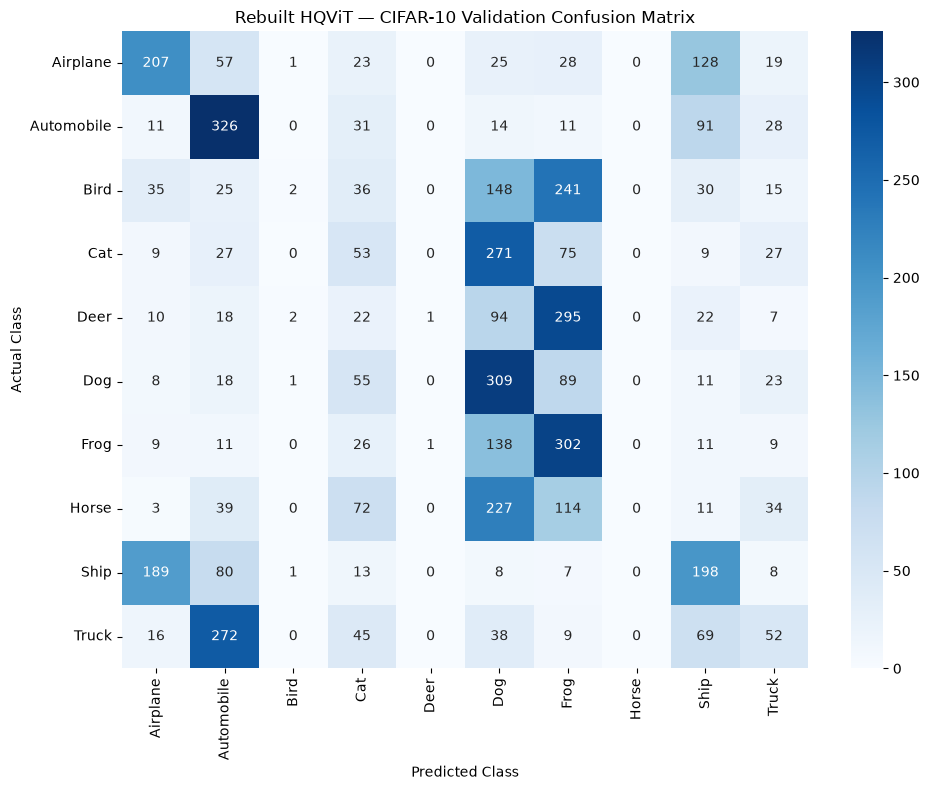


Evaluation artifacts saved successfully.


In [32]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# --------------------------------------------------
# 1. Load saved HQViT checkpoint
# --------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint_path = "models_clean/final_hqvit/rebuilt_hqvit_final.pt"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

HQViT.load_state_dict(checkpoint["model_state_dict"])
HQViT.to(device)
HQViT.eval()

# --------------------------------------------------
# 2. Validation loader
# --------------------------------------------------

validation_loader = DataLoader(
    validation_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

all_predictions = []
all_labels = []

# --------------------------------------------------
# 3. Generate predictions
# --------------------------------------------------

with torch.no_grad():
    for images, labels in validation_loader:

        images = images.to(device)

        outputs = HQViT(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

# --------------------------------------------------
# 4. Calculate metrics
# --------------------------------------------------

accuracy = accuracy_score(all_labels, all_predictions)

precision, recall, f1, support = precision_recall_fscore_support(
    all_labels,
    all_predictions,
    labels=list(range(10)),
    zero_division=0
)

print("\n========== HQViT VALIDATION RESULTS ==========")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Macro Precision: {precision.mean():.4f}")
print(f"Macro Recall:    {recall.mean():.4f}")
print(f"Macro F1-score:  {f1.mean():.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(10)),
    target_names=[
        "Airplane", "Automobile", "Bird", "Cat", "Deer",
        "Dog", "Frog", "Horse", "Ship", "Truck"
    ],
    zero_division=0
))

# --------------------------------------------------
# 5. Prediction distribution
# --------------------------------------------------

class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

prediction_counts = np.bincount(all_predictions, minlength=10)

distribution = pd.DataFrame({
    "Class": class_names,
    "Predicted Count": prediction_counts,
    "Recall": recall,
    "F1-score": f1
})

print("\nPREDICTION DISTRIBUTION")
display(distribution)

# --------------------------------------------------
# 6. Confusion matrix
# --------------------------------------------------

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(10))
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Rebuilt HQViT — CIFAR-10 Validation Confusion Matrix")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 7. Save evaluation results
# --------------------------------------------------

import os
os.makedirs("results/final_hqvit", exist_ok=True)

distribution.to_csv(
    "results/final_hqvit/class_metrics.csv",
    index=False
)

pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(
    "results/final_hqvit/confusion_matrix.csv"
)

print("\nEvaluation artifacts saved successfully.")